In [27]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs

import sys
import os

module_dir = (Path.cwd() / ".."/".." / "algorithms"/ "track_style_alg").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import helpers
from configs import *

import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel



<module 'processing' from '/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/algorithms/track_style_alg/processing.py'>

In [28]:
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks
df_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])
df_validation=df_validation.rename(columns={'vorticity': 'vo'})

In [29]:
len(df_validation['track_id'].unique())

467

In [30]:
#Load the tracks from the trackjson file
tracks = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo_lmin_6.trackjson')
tracks.metadata.processing

(ProcessingStep(operation='spectral_filter', enabled=True, parameters=mappingproxy({'method': 'sht', 'lmin': 6, 'lmax': 42, 'spectral_taper': 0.1})),)

In [31]:
df = helpers.tracks_to_points(tracks)
df

,track_id,time,lat,lon,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,object_moment_orientation_degrees,raw_value,vo
0,1,1998-12-14 18:00:00,-15.00,42.25,0.0,0.0,0.0,0.0,0.0,0.000010,0.000010
1,1,1998-12-15 00:00:00,-15.25,41.75,0.0,0.0,0.0,0.0,0.0,0.000011,0.000011
2,1,1998-12-15 06:00:00,-16.75,42.25,0.0,0.0,0.0,0.0,0.0,0.000014,0.000014
3,1,1998-12-15 12:00:00,-16.75,44.00,0.0,0.0,0.0,0.0,0.0,0.000013,0.000013
4,1,1998-12-15 18:00:00,-17.75,41.75,0.0,0.0,0.0,0.0,0.0,0.000013,0.000013
...,...,...,...,...,...,...,...,...,...,...,...
36349,6299,1999-02-27 06:00:00,50.75,-136.75,0.0,0.0,0.0,0.0,0.0,0.000079,0.000079
36350,6299,1999-02-27 12:00:00,51.75,-140.00,0.0,0.0,0.0,0.0,0.0,0.000062,0.000062
36351,6301,1999-02-27 06:00:00,-42.00,-40.00,0.0,0.0,0.0,0.0,0.0,0.000018,0.000018
36352,6301,1999-02-27 12:00:00,-40.75,-40.50,0.0,0.0,0.0,0.0,0.0,0.000023,0.000023


In [32]:
df_validation = val.clip_to_domain(df_validation, DOMAIN, TIME_RANGE)
len(df_validation['track_id'].unique())

208

In [33]:
tracks_validation = val.dataframe_to_tracks(df_validation, variable = 'vo', scale=1e-5)  # convert to s^-1

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


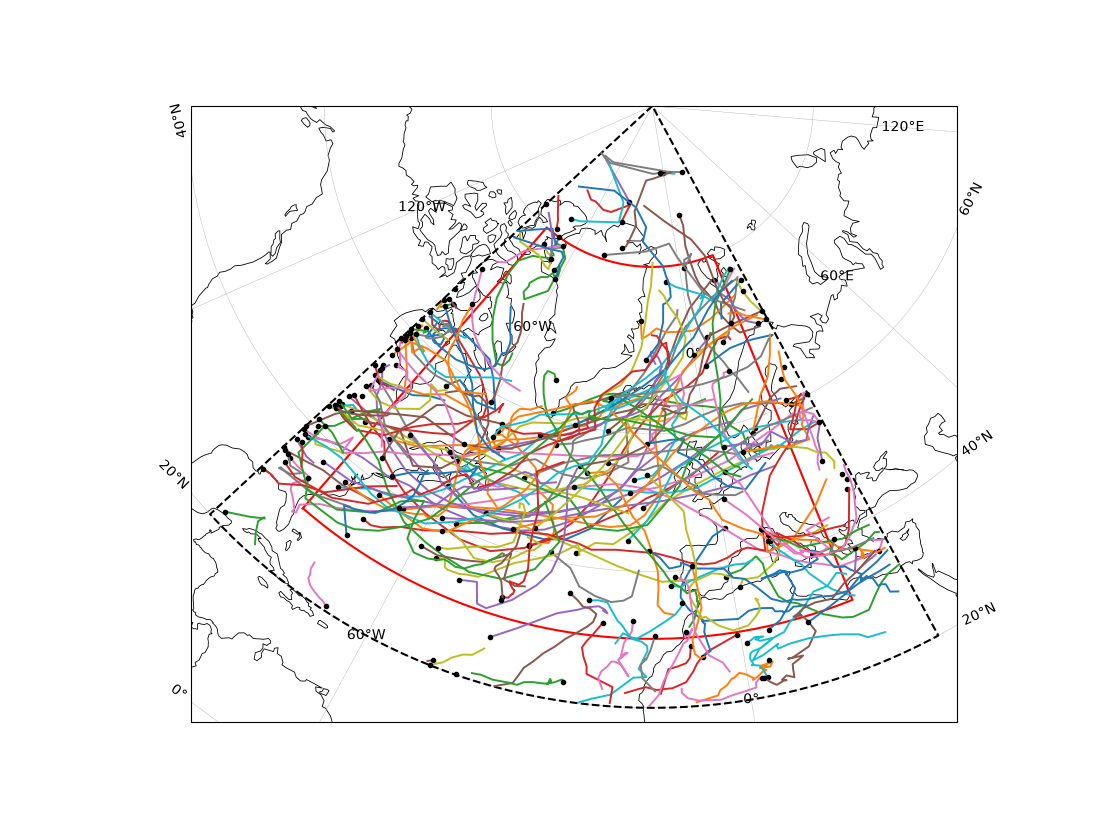

In [34]:
ax = val.plot_regional_tracks(tracks_validation, region=REGION, domain=DOMAIN) 

In [35]:
tracks_validation, summary_validation, points_validation = pro.postprocess_tracks(tracks_validation, **POSTPROCESS_CONFIG)

In [36]:
report = pro.filter_report(summary_validation)

raw tracks: 208, kept: 120


# Full globe tracks

In [37]:
df = val.clip_to_domain(df, DOMAIN, TIME_RANGE)
len(df['track_id'].unique())

519

In [38]:
tracks = val.dataframe_to_tracks(df, variable = 'vo', scale=1)  # already in s^-1


In [39]:
tracks, summary, points = pro.postprocess_tracks(tracks, **POSTPROCESS_CONFIG)

In [40]:
report = pro.filter_report(summary)


raw tracks: 519, kept: 124


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


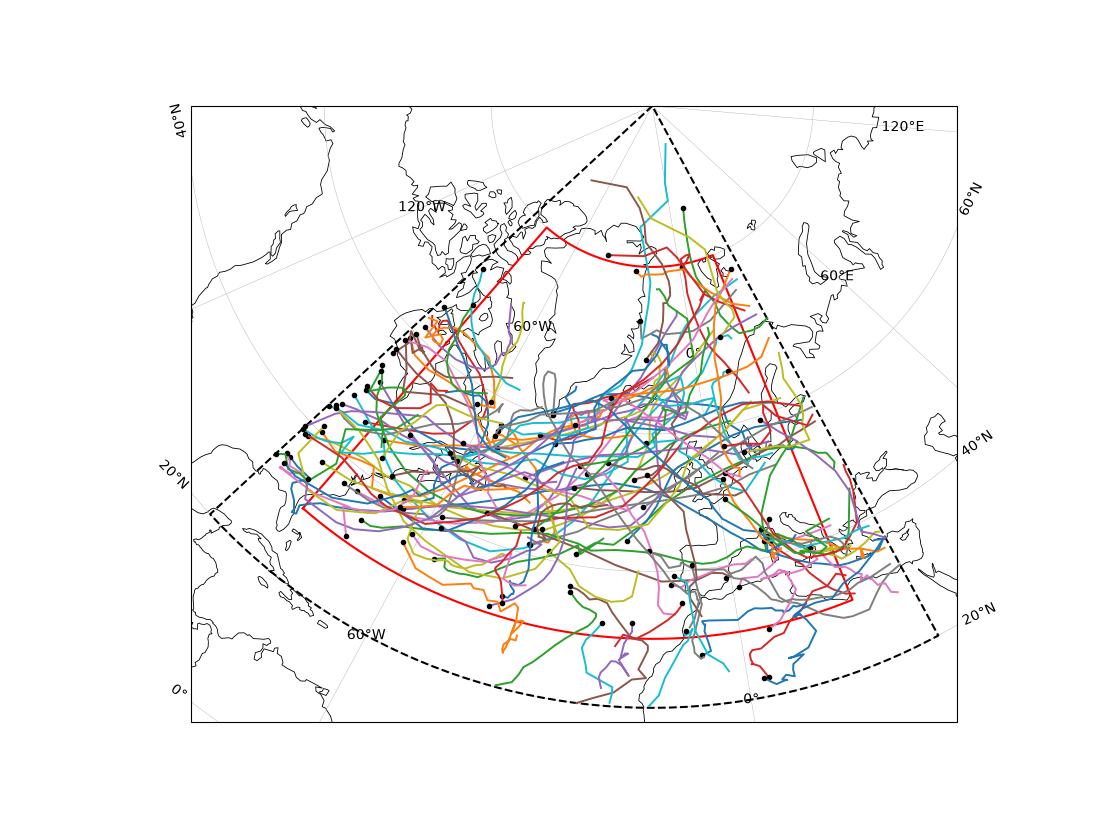

In [41]:
ax= val.plot_regional_tracks(tracks, region=REGION, domain=DOMAIN)

In [42]:
comparison, matches_df = val.compare_to_validation(tracks_validation, tracks, matching="global_assignment",
                                               max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                                               variable="vo")

In [43]:
matches_df

,reference_id,candidate_id,overlap_fraction,overlap_count,mean_sep_km,max_sep_km,ref_points,cand_points,ref_peak,cand_peak,n_eligible_candidates,intensity_bias,intensity_rmse
0,700,800,1.000000,23,11.007266,33.367902,23,23,0.000116,0.000116,1,8.996192e-08,2.185306e-07
1,800,600,1.000000,28,9.382665,26.148558,28,28,0.000061,0.000061,1,-4.257948e-08,1.637379e-07
2,1100,16800,1.000000,20,13.927060,29.382206,20,20,0.000073,0.000073,1,1.425945e-07,2.950547e-07
3,5300,12900,0.965517,14,23.691361,74.043873,14,15,0.000032,0.000032,1,-9.425807e-08,4.434420e-07
4,7900,20200,1.000000,24,12.834802,78.872794,24,24,0.000120,0.000120,1,1.054548e-07,2.038746e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,244700,587200,0.645161,10,8.570940,13.895571,21,10,0.000056,0.000056,1,9.376175e-09,1.801456e-07
108,246100,590400,1.000000,11,9.935359,22.570465,11,11,0.000108,0.000108,1,1.942465e-07,2.361911e-07
109,252000,621700,1.000000,9,8.360175,17.262752,9,9,0.000098,0.000098,1,5.903704e-08,1.141428e-07
110,252100,602500,0.947368,9,38.482219,127.324242,9,10,0.000026,0.000030,1,-2.990581e-07,9.059681e-07


In [44]:
# result table 
results_df = pd.Series({
    "Hits": comparison.tp,
    "Miss": comparison.fn,
    "Extra": comparison.fp,
    "F1": comparison.f1, #
    "Precision": comparison.precision,
    "Recall": comparison.recall,
})
results_df

Hits         112.000000
Miss           8.000000
Extra         12.000000
F1             0.918033
Precision      0.903226
Recall         0.933333
dtype: float64

Number of verified tracks: 112
Number of extra tracks: 12
Number of verified validation tracks: 112
Number of missed tracks: 8
22.75
22.689558


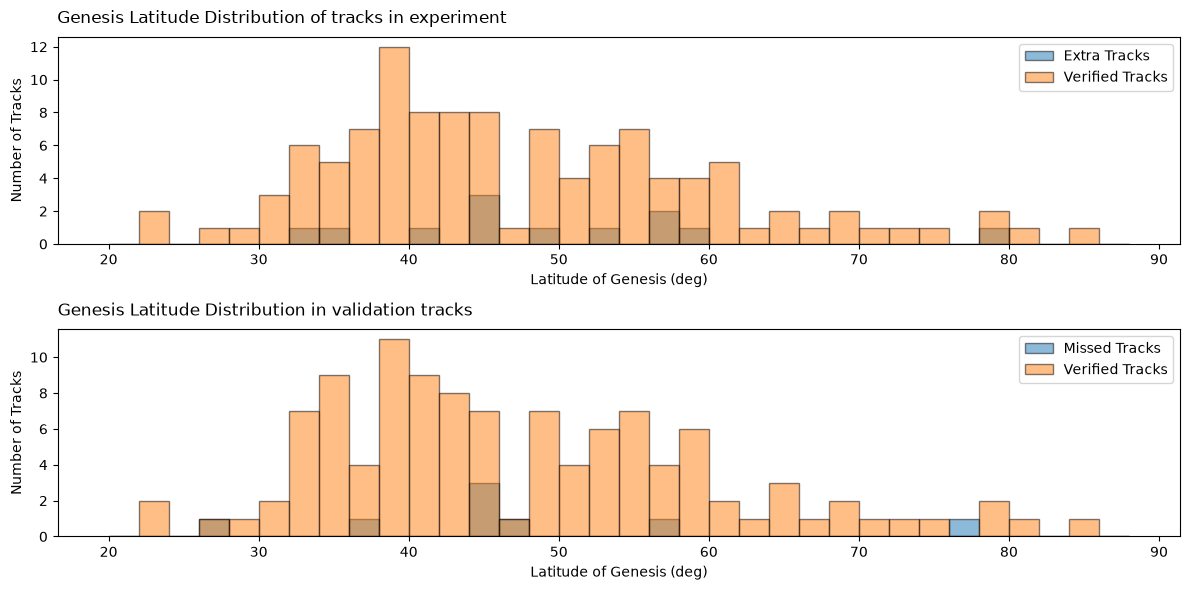

In [45]:
#creating list for verified
verified_tracks = matches_df['candidate_id']
verified_val = matches_df['reference_id']

#remember to filter the summary dataframes to only include the tracks that were kept
summary_val_filtered = summary_validation[summary_validation['keep'] == True]
summary_filtered = summary[summary['keep'] == True]


kept_tracks = summary_filtered[summary_filtered['track_id'].isin(verified_tracks)]
extra_tracks = summary_filtered[~summary_filtered['track_id'].isin(verified_tracks)]

kept_val_tracks = summary_val_filtered[summary_val_filtered['track_id'].isin(verified_val)]
missed_tracks = summary_val_filtered[~summary_val_filtered['track_id'].isin(verified_val)]




print(f"Number of verified tracks: {len(kept_tracks)}")
print(f"Number of extra tracks: {len(extra_tracks)}")
print(f"Number of verified validation tracks: {len(kept_val_tracks)}")
print(f"Number of missed tracks: {len(missed_tracks)}")

print(np.min(kept_tracks["lat_genesis"].values))
print(np.min(kept_val_tracks["lat_genesis"].values))

genesis_ver = kept_tracks["lat_genesis"].values
genesis_missed = missed_tracks["lat_genesis"].values
genesis_ex = extra_tracks["lat_genesis"].values
genesis_val = kept_val_tracks["lat_genesis"].values

counts, edges = np.histogram(genesis_ver, bins=np.arange(20, 90, 2), density=False)
counts_missed, edges_missed = np.histogram(genesis_missed, bins=np.arange(20, 90, 2), density=False)
counts_dis, edges_dis = np.histogram(genesis_ex, bins=np.arange(20, 90, 2), density=False)
counts_val, edges_val = np.histogram(genesis_val, bins=np.arange(20, 90, 2), density=False)

fig, ax = plt.subplots(2,1,figsize=(12, 6), sharex=False)
ax[0].bar(edges_dis[:-1], counts_dis, width=2, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=2, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)


ax[0].set_xlabel("Latitude of Genesis (deg)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Genesis Latitude Distribution of tracks in experiment", fontsize=12, pad=10, x=0.2)
ax[0].legend()

ax[1].set_xlabel("Latitude of Genesis (deg)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Genesis Latitude Distribution in validation tracks", fontsize=12, pad=10, x=0.185)
ax[1].legend()

plt.tight_layout()

In [46]:
ref_pts = helpers.tracks_to_points(tracks_validation)
can_pts = helpers.tracks_to_points(tracks)
taken_by = dict(zip(matches_df["candidate_id"], matches_df["reference_id"]))   # candidate -> its reference
takes    = dict(zip(matches_df["reference_id"], matches_df["candidate_id"]))   # reference -> its candidate

def closest_partners(own, others, ids, other_matched):
    pts = own[own["track_id"].isin(ids)].merge(others, on="time", suffixes=("", "_o"))   # shared time steps only
    pts["d_km"] = helpers.haversine_km(pts["lat"], pts["lon"], pts["lat_o"], pts["lon_o"])
    n = own.groupby("track_id").size()
    n_o = others.groupby("track_id").size()
    g = (pts.groupby(["track_id", "track_id_o"])
            .agg(common=("time", "size"), mean_sep_km=("d_km", "mean"), min_sep_km=("d_km", "min"))
            .reset_index())
    g["overlap"] = 2 * g["common"] / (g["track_id"].map(n) + g["track_id_o"].map(n_o))
    g["partner_already_matched"] = g["track_id_o"].map(other_matched).notna()
    g = g[g["min_sep_km"] < 500].sort_values(["track_id", "mean_sep_km"])
    return g.groupby("track_id").head(2)          # the two closest partners per track

print("MISSED tracks vs all of your tracks")
print(closest_partners(ref_pts, can_pts, missed_tracks["track_id"], taken_by).round(2))
print("\nEXTRA tracks vs all reference tracks")
print(closest_partners(can_pts, ref_pts, extra_tracks["track_id"], takes).round(2))

MISSED tracks vs all of your tracks
    track_id  track_id_o  common  mean_sep_km  min_sep_km  overlap  \
46     63200      169300      20       307.94        1.86     0.87   
49     77000      114600      14       326.31        3.26     0.97   
77    227800      628300       9       245.27        3.73     1.00   

    partner_already_matched  
46                    False  
49                    False  
77                    False  

EXTRA tracks vs all reference tracks
     track_id  track_id_o  common  mean_sep_km  min_sep_km  overlap  \
3      114600       77000      14       326.31        3.26     0.97   
21     169300       63200      20       307.94        1.86     0.87   
107    628300      227800       9       245.27        3.73     1.00   

     partner_already_matched  
3                      False  
21                     False  
107                    False  


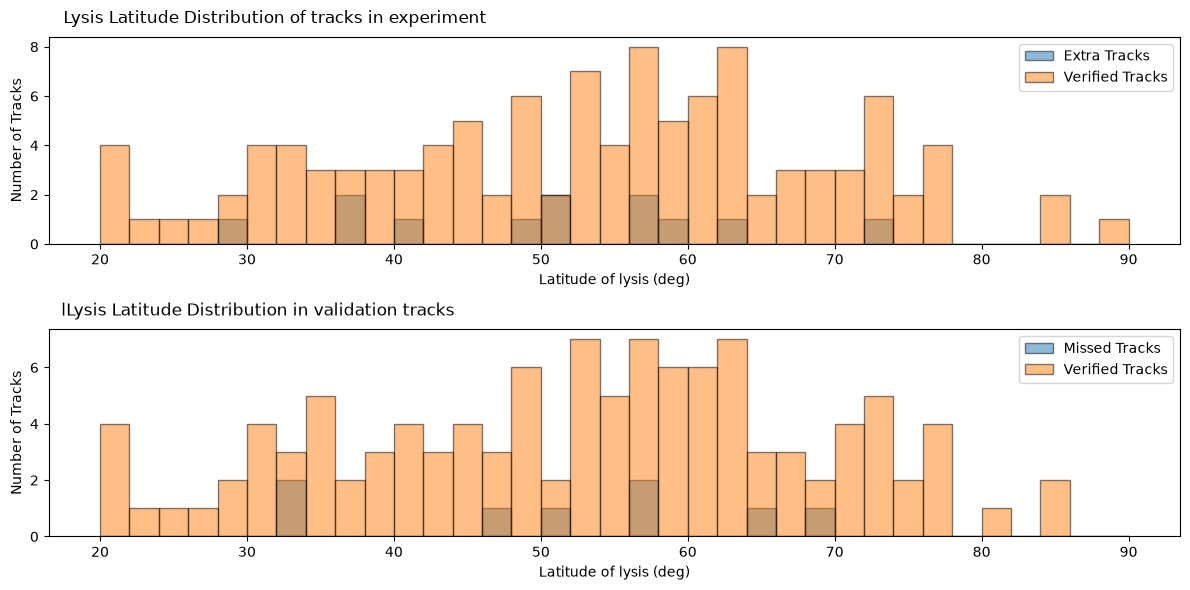

In [47]:
lysis_ver = kept_tracks["lat_lysis"].values
lysis_missed = missed_tracks["lat_lysis"].values
lysis_ex = extra_tracks["lat_lysis"].values
lysis_val = kept_val_tracks["lat_lysis"].values

counts, edges = np.histogram(lysis_ver, bins=np.arange(20, 92, 2), density=False)
counts_missed, edges_missed = np.histogram(lysis_missed, bins=np.arange(20, 92, 2), density=False)
counts_dis, edges_dis = np.histogram(lysis_ex, bins=np.arange(20, 92, 2), density=False)
counts_val, edges_val = np.histogram(lysis_val, bins=np.arange(20, 92, 2), density=False)

fig, ax = plt.subplots(2,1,figsize=(12, 6), sharex=False)
ax[0].bar(edges_dis[:-1], counts_dis, width=2, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=2, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=2, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)


ax[0].set_xlabel("Latitude of lysis (deg)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Lysis Latitude Distribution of tracks in experiment", fontsize=12, pad=10, x=0.2)
ax[0].legend()

ax[1].set_xlabel("Latitude of lysis (deg)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("lLysis Latitude Distribution in validation tracks", fontsize=12, pad=10, x=0.185)
ax[1].legend()

plt.tight_layout()

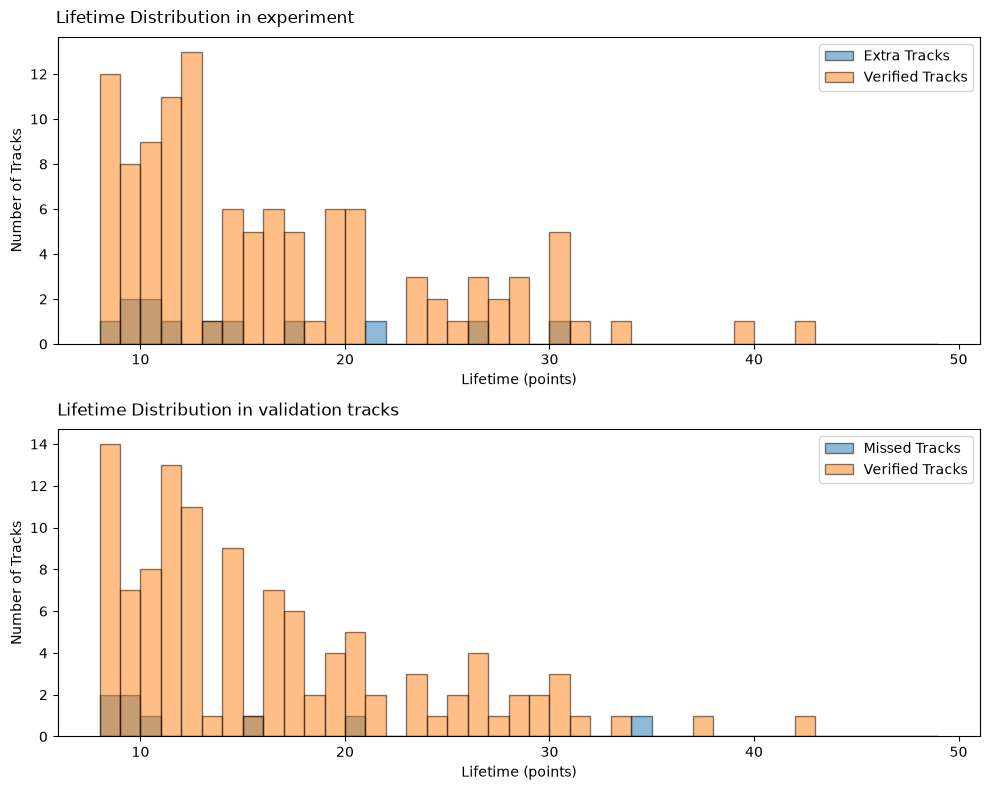

In [48]:
lifetime = kept_tracks["n_points"].values
lifetime_missed = missed_tracks["n_points"].values
lifetime_ex = extra_tracks["n_points"].values
lifetime_val = kept_val_tracks["n_points"].values

counts, edges = np.histogram(lifetime, bins=np.arange(8, 50, 1))
counts_missed, edges_missed = np.histogram(lifetime_missed, bins=np.arange(8, 50, 1))
counts_dis, edges_dis = np.histogram(lifetime_ex, bins=np.arange(8, 50, 1))
counts_val, edges_val = np.histogram(lifetime_val, bins=np.arange(8, 50, 1))

fig, ax = plt.subplots(2,1,figsize=(10, 8))
ax[0].bar(edges_dis[:-1], counts_dis, width=1, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=1, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[0].set_xlabel("Lifetime (points)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Lifetime Distribution in experiment", fontsize=12, pad=10, x=0.16)
ax[0].legend()

ax[1].set_xlabel("Lifetime (points)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Lifetime Distribution in validation tracks", fontsize=12, pad=10, x=0.185)
ax[1].legend()

plt.tight_layout()

5.8737457948154805
4.3954565
4.620629806595391
5.872454


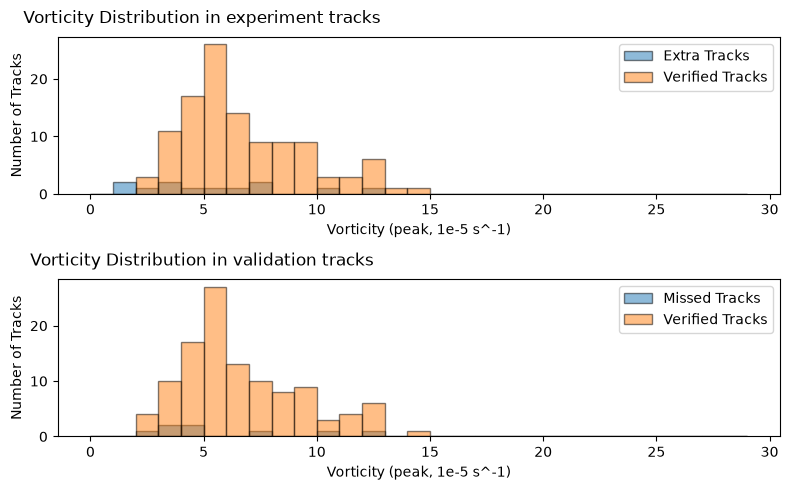

In [49]:
vo_peak = kept_tracks["vo_peak"].values*1e5
vo_peak_missed = missed_tracks["vo_peak"].values*1e5
vo_peak_ex = extra_tracks["vo_peak"].values*1e5
vo_peak_val = kept_val_tracks["vo_peak"].values*1e5

counts, edges = np.histogram(vo_peak, bins=np.arange(0, 30, 1))
counts_missed, edges_missed = np.histogram(vo_peak_missed, bins=np.arange(0, 30, 1))
counts_dis, edges_dis = np.histogram(vo_peak_ex, bins=np.arange(0, 30, 1))
counts_val, edges_val = np.histogram(vo_peak_val, bins=np.arange(0, 30, 1))
fig, ax = plt.subplots(2,1, figsize=(8, 5))
ax[0].bar(edges_dis[:-1], counts_dis, width=1, align="edge", edgecolor="black", label="Extra Tracks", alpha=0.5)
ax[0].bar(edges[:-1], counts, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)

ax[1].bar(edges_missed[:-1], counts_missed, width=1, align="edge", edgecolor="black", label="Missed Tracks", alpha=0.5)
ax[1].bar(edges_val[:-1], counts_val, width=1, align="edge", edgecolor="black", label="Verified Tracks", alpha=0.5)


ax[0].set_xlabel("Vorticity (peak, 1e-5 s^-1)")
ax[0].set_ylabel("Number of Tracks")
ax[0].set_title("Vorticity Distribution in experiment tracks", fontsize=12, pad=10, x=0.2)
ax[0].legend()

ax[1].set_xlabel("Vorticity (peak, 1e-5 s^-1)")
ax[1].set_ylabel("Number of Tracks")
ax[1].set_title("Vorticity Distribution in validation tracks", fontsize=12, pad=10, x=0.2)
ax[1].legend()

plt.tight_layout()

print(np.median(kept_tracks["vo_peak"].values*1e5))
print(np.median(missed_tracks["vo_peak"].values*1e5))
print(np.median(extra_tracks["vo_peak"].values*1e5))
print(np.median(kept_val_tracks["vo_peak"].values*1e5))

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


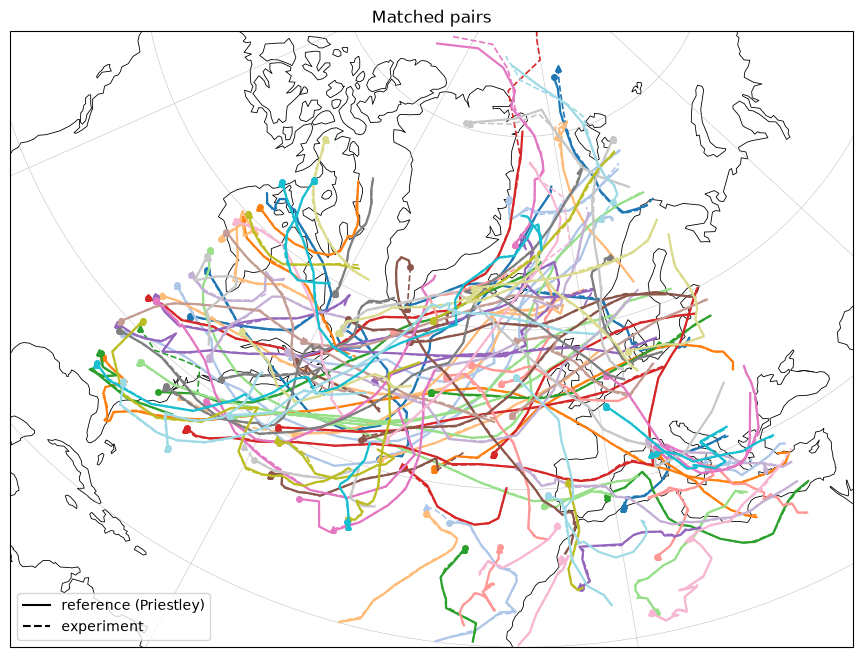

In [50]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

# look up tracks by id
ref_by_id = {tr.track_id: tr for tr in tracks_validation}
cand_by_id = {tr.track_id: tr for tr in tracks}

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 85], crs=pc)

colors = plt.cm.tab20(np.linspace(0, 1, len(matches_df)))
for row, c in zip(matches_df.itertuples(), colors):
    ref = ref_by_id[int(row.reference_id)]
    cand = cand_by_id[int(row.candidate_id)]
    ax.plot(ref.lons, ref.lats, "-", color=c, lw=1.6, transform=pc)
    ax.plot(cand.lons, cand.lats, "--", color=c, lw=1.2, transform=pc)
    ax.plot(ref.lons[0], ref.lats[0], "o", color=c, ms=4, transform=pc)    # reference start
    ax.plot(cand.lons[0], cand.lats[0], "^", color=c, ms=4, transform=pc)  # experiment start

ax.plot([], [], "k-", label="reference (Priestley)")
ax.plot([], [], "k--", label="experiment")
ax.legend(loc="lower left")
ax.set_title(f"Matched pairs")
plt.show()

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


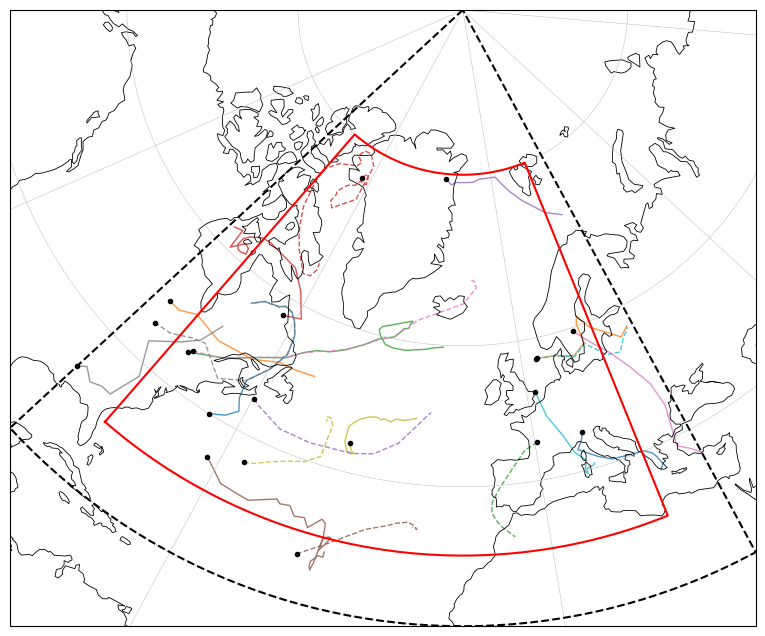

In [51]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)


for tr in tracks:
    if tr.track_id in extra_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)

for tr in tracks_validation:
    if tr.track_id in missed_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "--", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
for box, style in ((DOMAIN, dict(color="k", linestyle="--")), (REGION, dict(color="red"))):
        # densify the edges so they follow parallels/meridians in the projection
        lo = np.linspace(box[0], box[1], 100)
        la = np.linspace(box[2], box[3], 100)
        xs = np.concatenate([lo, np.full(100, box[1]), lo[::-1], np.full(100, box[0])])
        ys = np.concatenate([np.full(100, box[2]), la, np.full(100, box[3]), la[::-1]])
        ax.plot(xs, ys, lw=1.5, transform=pc, **style)  


Number of missed tracks: 8
Number of missed tracks plotted: 8


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


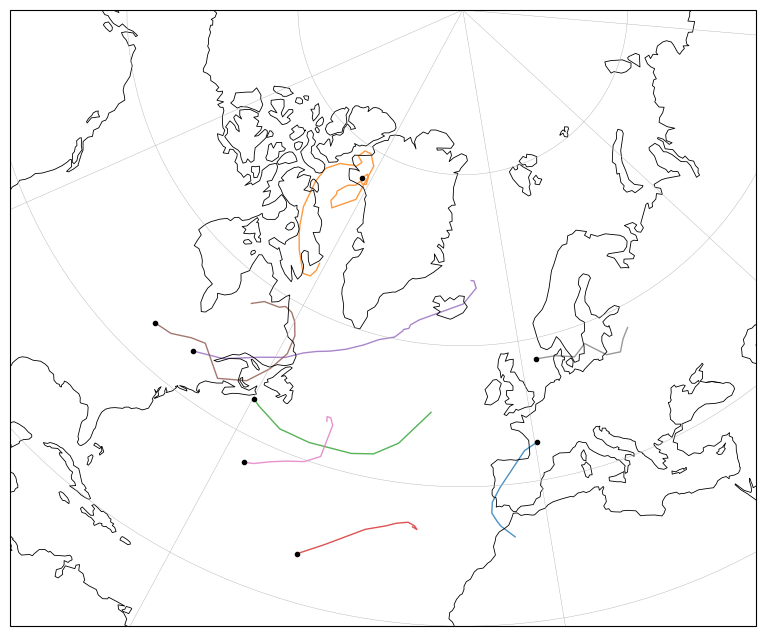

In [52]:
pc = ccrs.PlateCarree()
proj = ccrs.LambertConformal(central_longitude=-15, central_latitude=55)

fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": proj})
ax.coastlines(linewidth=0.6)
ax.gridlines(linewidth=0.3)
ax.set_extent([DOMAIN[0], DOMAIN[1], DOMAIN[2], 90], crs=pc)
i =0
print(f"Number of missed tracks: {len(missed_tracks)}")
for tr in tracks_validation:
    if tr.track_id in missed_tracks['track_id'].values:
        ax.plot(tr.lons, tr.lats, "-", alpha=0.8, lw=1, transform=pc, zorder=0)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
        i+=1
print(f"Number of missed tracks plotted: {i}")